[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/15-projects/p02-regression-and-segmentation/colab_quickstart.ipynb)

# P2 quickstart - regression and customer segmentation

Part A predicts diabetes progression (including gradient descent written by hand). Part B groups synthetic customers with K-means. CPU only, about 15 seconds.

## 1. Get the code
In Colab this clones the repo. If the project folder already exists, the clone is skipped.

In [1]:
import os, subprocess, sys
from pathlib import Path

PROJECT = "15-projects/p02-regression-and-segmentation"
if Path("main.py").exists() and Path("requirements.txt").exists():
    print("Already inside the project folder - no clone needed.")
elif Path("../../" + PROJECT).exists():
    os.chdir("../../" + PROJECT)          # repo already on disk two levels up
else:
    if not Path("AI-Engineer").exists():  # first run in Colab: download the repo
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/vvvvvivekkk/AI-Engineer.git"], check=True)
    os.chdir(Path("AI-Engineer") / PROJECT)
print("Working folder:", Path.cwd())

Already inside the project folder - no clone needed.
Working folder: /home/claude/AI-Engineer/15-projects/p02-regression-and-segmentation


## 2. Install packages (Colab only)

In [2]:
import sys, subprocess
from pathlib import Path
# Only install in Colab. Locally you already did "pip install -r requirements.txt" in a venv.
# Colab ships its own PyTorch, so we skip the torch line to save a big download.
if "google.colab" in sys.modules:
    reqs = [l for l in Path("requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith(("#", "torch"))]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=True)
    print("installed", len(reqs), "packages")
else:
    print("Not in Colab - skipping install.")

Not in Colab - skipping install.


## 3. (Re)create the sample data
Seeded, so the file is identical every time.

In [3]:
!{sys.executable} make_data.py

wrote data/diabetes.csv and data/customers.csv


## 4. Run both parts

In [4]:
!{sys.executable} main.py

=== Part A: diabetes progression (test set) ===
               model   MAE  RMSE    R2
our_gradient_descent 42.79 53.85  0.45
   linear_regression 42.79 53.85  0.45
      ridge(alpha=1) 42.81 53.78  0.45
   gradient_boosting 42.70 52.67  0.48
       baseline_mean 64.01 73.22 -0.01
best model: gradient_boosting
hand-written GD vs scikit-learn: largest weight difference = 0.0040



=== Part B: customer segmentation ===
 k  inertia  silhouette
 2  804.655       0.514
 3  307.870       0.633
 4  102.033       0.715
 5   91.895       0.612
 6   82.027       0.514
 7   73.611       0.426
 8   67.047       0.310
chosen k = 4 (highest silhouette)
         annual_spend  visits_per_month  days_since_last_visit  customers                name
segment                                                                                      
0              2084.5               5.9                   89.9        149             at risk
1               795.4               2.9                   20.6        151          occasional
2               354.0               1.3                  198.0        150                lost
3              2983.7              12.0                    6.4        150  loyal big spenders
agreement with the hidden true groups (adjusted Rand index, 1 = perfect): 0.996

Charts and tables written to /home/claude/AI-Engineer/15-projects/p02-regression-and-segme

## 5. Look at the charts
Left: gradient descent's error falling. Right: residuals. Then the elbow, silhouette and PCA plots for segmentation.

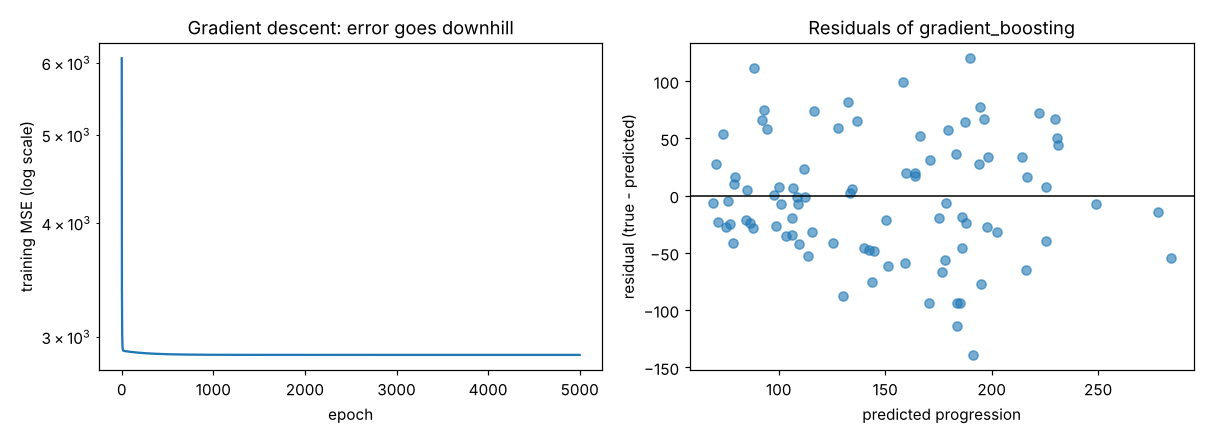

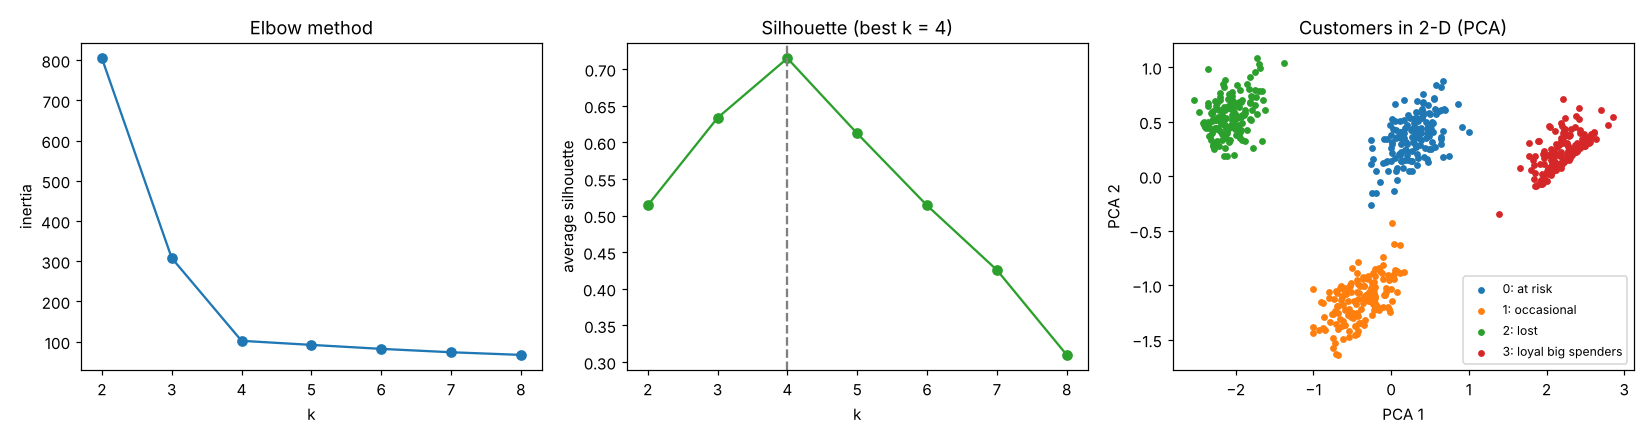

In [5]:
from IPython.display import Image, display
display(Image('reports/regression.png'))
display(Image('reports/segmentation.png'))

## 6. Run the tests

In [6]:
!{sys.executable} -m pytest -q

.

.

.                                                                      [100%]
3 passed in 2.36s
